## Cierre recuperado de FC-A, corrida1 — solo lectura

El entrenamiento, test y checkpoint terminaron antes de un fallo de presentación por Styler. El notebook fallido queda archivado. Estas celdas nuevas leen las salidas guardadas sin repetir cálculos del modelo.

In [1]:
from pathlib import Path
import pandas as pd,json,sys
import matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd();sys.path.insert(0,str(ROOT/'scripts'))
from registro_notebook import mostrar_figura
run=next((ROOT/'resultados/paralelo/EXP-011').glob('RUN-*-fc-a-01'))
dest=ROOT/'resultados/preparacion/ampliacion-fc/recuperacion-fc-a-01'
dest.mkdir(exist_ok=False)
print('Recuperación SIN reentrenar:',run.name)
print((run/'metricas.json').read_text(encoding='utf8'))
print((run/'modelo-guardado.json').read_text(encoding='utf8'))
display(pd.read_csv(run/'tiempos.csv'))
e=pd.read_csv(run/'epocas.csv');display(e)

Recuperación SIN reentrenar: RUN-20261118T134323Z-fc-a-01
{
  "modelo": "FC-A",
  "repeticion": 1,
  "test": {
    "accuracy": 0.517241358757019,
    "loss": 1.5723273754119873
  },
  "epocas": 15,
  "pasos": 1440,
  "entrenamiento_s": 14.829318,
  "evaluacion_cpu_s": 0.3873936,
  "comparabilidad": "Datos, estado inicial, arquitectura y pasos equivalentes; CPU histórica; RNG interno diferente"
}

{
  "ruta": "data/EXP-011/RUN-20261118T134323Z-fc-a-01/FC-A-CUDA.keras",
  "sha256": "8e48d963c505b15e58b9d6955224d372ad7c40a26444bf9a2d6efe3744c80808",
  "estado_canonico_sha256": "c66c555884d37724a8666c9bdd52b891f4d9dc5b96bd82a5e1afe8d27f0b686d",
  "optimizer_iterations": 1440
}



,experimento_id,run_id,modelo,repeticion,fase,tipo_medicion,duracion_s,configuracion_sha256,inicio_utc,fin_utc
0,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,preparacion_cpu,pared,8.071974,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
1,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,entrenamiento_FC-A,pared,14.829318,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,2026-11-18T13:43:57.125623+00:00,2026-11-18T13:44:11.955015+00:00
2,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,validacion_anidada_FC-A,pared,3.468008,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
3,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,h2d_inicial,evento_device,0.014885,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
4,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,h2d_lotes,evento_device,1.717293,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
5,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,forward_loss,evento_device,1.927660,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
6,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,backward,evento_device,2.592832,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
7,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,adam_metricas,evento_device,0.791590,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
8,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,d2h_control,evento_device,0.147047,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN
9,EXP-011,RUN-20261118T134323Z-fc-a-01,FC-A,1,d2h_modelo,evento_device,0.029952,9643fd18784297f41f508c57dcdb3c6cd474c29a03b82f...,NaN,NaN


,modelo,repeticion,epoca,pasos_acumulados,train_loss,train_accuracy,val_loss,val_accuracy,pared_epoca_s,validacion_cpu_s
0,FC-A,1,1,96,4.118540,0.078325,3.267035,0.075862,1.206152,0.246464
1,FC-A,1,2,192,3.082785,0.130624,3.051234,0.181609,0.975817,0.233441
2,FC-A,1,3,288,2.908259,0.164286,2.749791,0.227203,0.993925,0.245106
3,FC-A,1,4,384,2.765812,0.186864,2.527188,0.245977,0.958016,0.225862
4,FC-A,1,5,480,2.670916,0.200985,2.365644,0.288123,0.954283,0.226823
5,FC-A,1,6,576,2.568258,0.224138,2.312251,0.304598,0.951552,0.227452
6,FC-A,1,7,672,2.473478,0.247291,2.161073,0.358621,0.975409,0.226906
7,FC-A,1,8,768,2.351817,0.271921,2.005586,0.406130,0.968237,0.235531
8,FC-A,1,9,864,2.259944,0.293596,1.926897,0.406897,0.964973,0.228853
9,FC-A,1,10,960,2.213015,0.301149,1.895587,0.430651,0.964624,0.224245


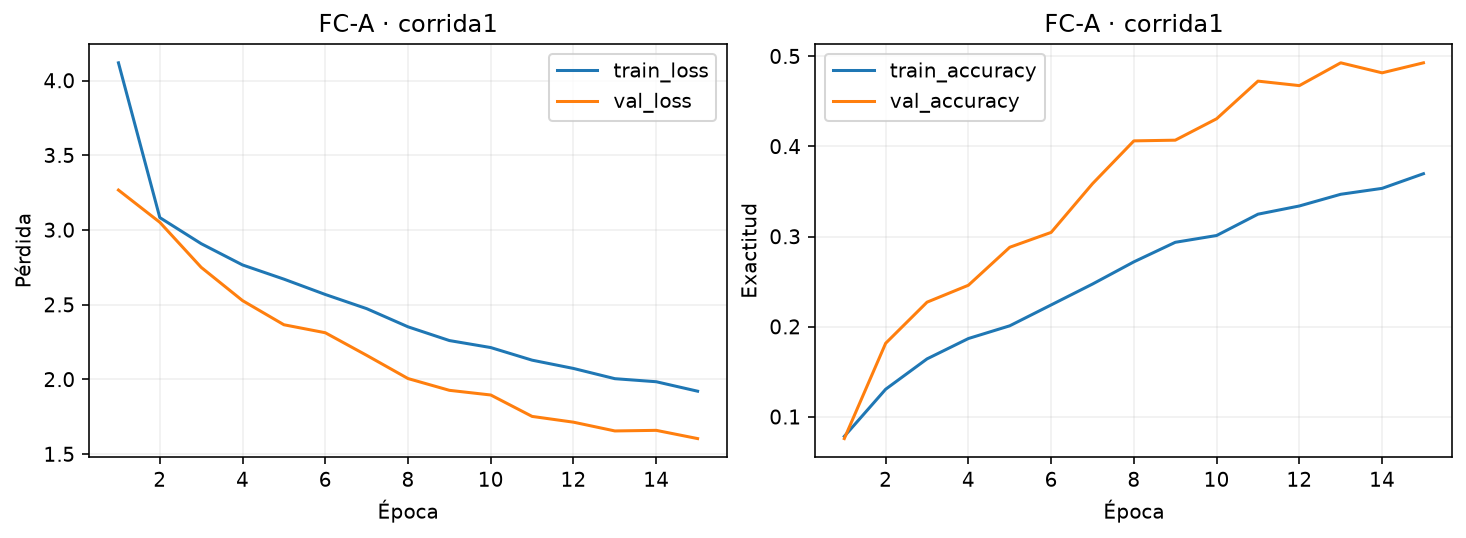

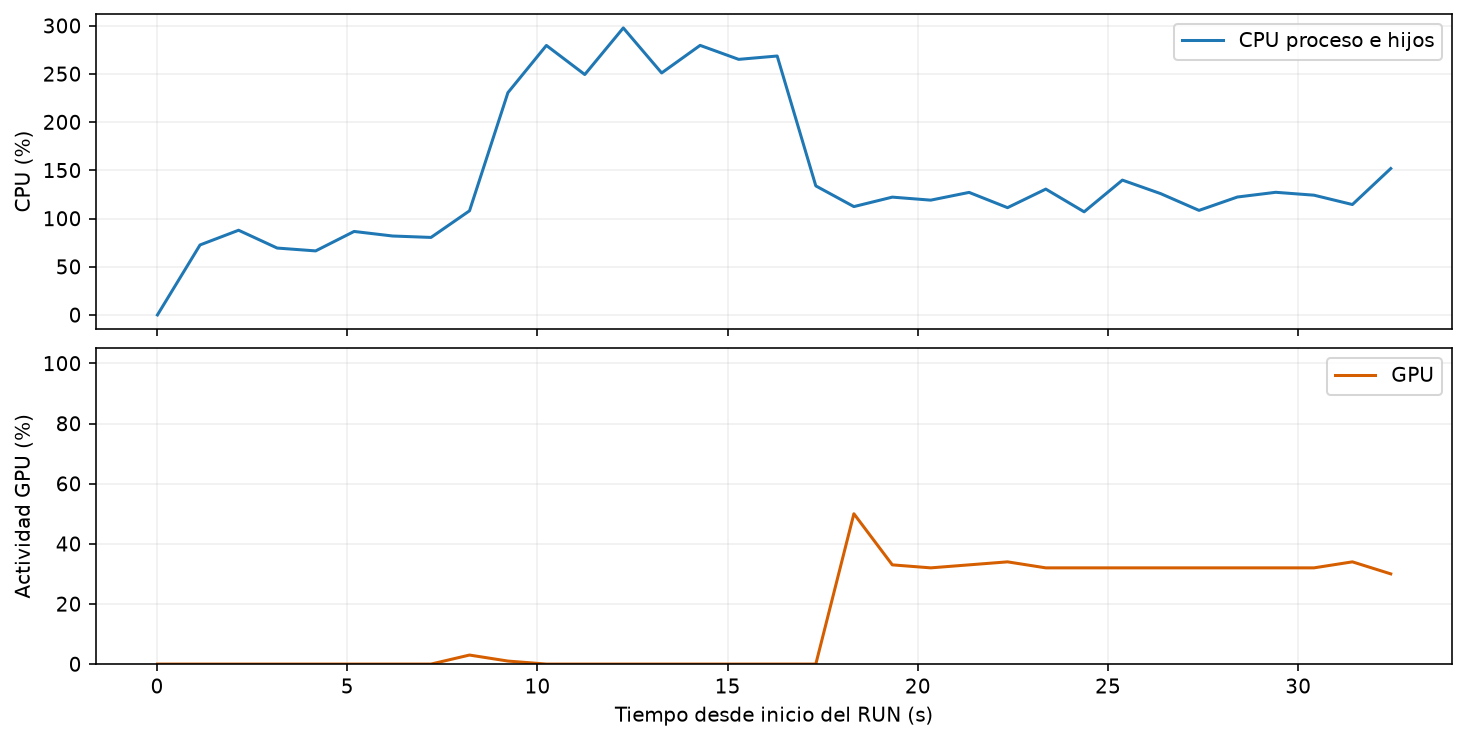

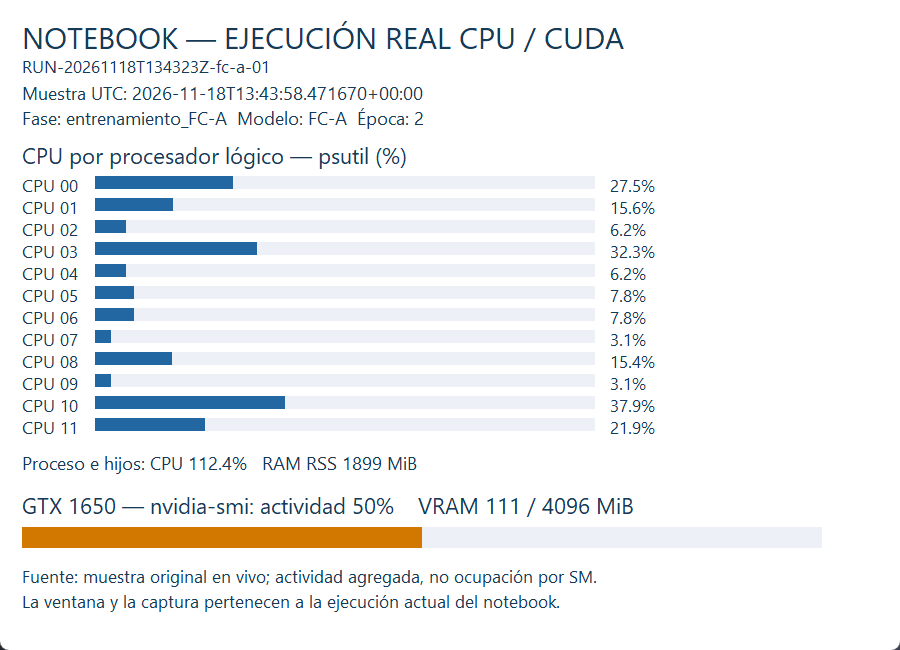

In [2]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,keys,title in zip(axes,[('train_loss','val_loss'),('train_accuracy','val_accuracy')],['Pérdida','Exactitud']):
    for key in keys:ax.plot(e.epoca,e[key],label=key)
    ax.set(xlabel='Época',ylabel=title,title='FC-A · corrida1');ax.legend();ax.grid(alpha=.2)
fig.savefig(dest/'curvas.png',dpi=160);fig.savefig(dest/'curvas.svg');mostrar_figura(fig)
r=pd.read_csv(run/'recursos.csv')
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
axes[0].plot(r.transcurrido_s,r.cpu_procesos_pct,label='CPU proceso e hijos');axes[0].set(ylabel='CPU (%)')
axes[1].plot(r.transcurrido_s,r.gpu_util_pct,color='#D55E00',label='GPU');axes[1].set(xlabel='Tiempo desde inicio del RUN (s)',ylabel='Actividad GPU (%)',ylim=(0,105))
for ax in axes:ax.legend();ax.grid(alpha=.2)
fig.savefig(dest/'recursos.png',dpi=160);fig.savefig(dest/'recursos.svg');mostrar_figura(fig)
for image in run.glob('captura-*.png'):display(Image(filename=str(image)))